In [1]:
import os
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras

from tensorflow.keras import layers, models
from keras.models import Sequential, Model
from loss import custom_loss
from keras.losses import MeanSquaredError
from keras.layers import *
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

import importlib

''' NB: Warning messages are silenced! Comment out for more detailed debugging'''
import warnings
warnings.filterwarnings("ignore")

2026-03-15 22:49:39.678126: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import OptimizedDataGenerator_v2
from OptimizedDataGenerator_v2 import OptimizedDataGenerator as NewDG
from loss import *
import models
importlib.reload(models)
importlib.reload(OptimizedDataGenerator_v2)
from models import var_network
from models import CreateModel

from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler
# from models.models import CreateModel # Conv2D model

from dataset_utils import add_noise

import matplotlib.pyplot as plt
pi = 3.14159265359

maxval=1e9
minval=1e-9

In [12]:
SQLayer = SoftQuantizeLayer(
        n_bits=2,
        # initial_thresholds = [247.80, 668.41, 1662.85],
        initial_thresholds = [-100, 300, 1200],
        # initial_levels = [0.0, 0.33333, 0.66667, 1.0],
        initial_levels = [0.0, 1.0, 2.0, 3.0],
        threshold_offset = -5e3, #80.0,
        # initial_range=[-1.0, 1.0],
        trainable_levels=False,
        trainable_thresholds=True,
        initial_k=40,
        trainable_k=False,
        name='soft_quantizer_output'
    )

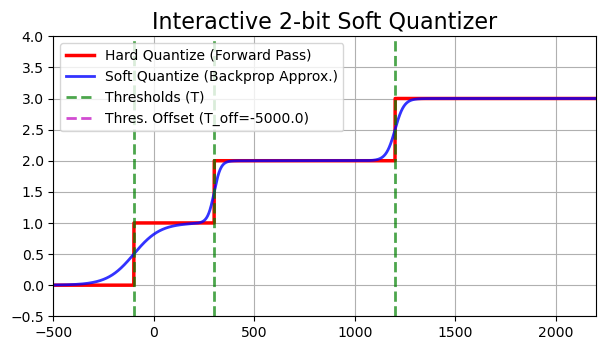

In [14]:
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

n_bits = 2
# num_levels = 2 ** n_bits
# B = num_levels - 1
# initial_k_val = 50.0
# initial_levels = np.array([0.0, 1.0, 2.0, 3.0], dtype=np.float32)
# threshold_offset = 80.0
# initital_thresholds = np.array([400.0, 800.0, 2000.0], dtype=np.float32)

# layer = SoftQuantizeLayer(
#     n_bits=n_bits,
#     initial_k=initial_k_val,
#     initial_levels=initial_levels,
#     threshold_offset=threshold_offset,
#     initial_thresholds=initital_thresholds,
# )
layer = SQLayer
x_input = tf.constant(np.linspace(-500, 2200, 3000), dtype=tf.float32)
layer.build(input_shape=x_input.shape)

# Current absolute values
L_abs0 = layer.levels.numpy().astype(np.float32)      # (L,)
T_abs0 = layer.thresholds.numpy().astype(np.float32)  # (B,)

fig, ax = plt.subplots(figsize=(7, 10))
plt.subplots_adjust(bottom=0.60)

y_hard_initial = layer._hard_quantize(x_input, layer.levels, layer.thresholds)
y_soft_initial = layer._soft_quantize(x_input, layer.k, layer.levels, layer.thresholds, layer.tau)

(line_hard,) = ax.plot(x_input, y_hard_initial, 'r-', lw=2.5, label='Hard Quantize (Forward Pass)')
(line_soft,) = ax.plot(x_input, y_soft_initial, 'b-', alpha=0.8, lw=2.0, label='Soft Quantize (Backprop Approx.)')

vlines = ax.vlines(layer.thresholds.numpy(), -0.5, 4.0,
                   colors='g', lw=2, alpha=0.7, linestyles='--', label='Thresholds (T)')
ax.vlines(layer.threshold_offset, -0.5, 4.0,
          colors='m', lw=2, alpha=0.7, linestyles='--', label=f'Thres. Offset (T_off={SQLayer.threshold_offset})', )

ax.set_title(f"Interactive {n_bits}-bit Soft Quantizer", fontsize=16)
ax.legend(loc='upper left')
ax.grid(True)
ax.set_xlim(-500,2200)
ax.set_ylim(-0.5, 4.0)



plt.show()